# Check prior sensitivity in Meridian without refitting: regional (geo-level) model

Fit the model **once**, then reweight the saved posterior draws to see what a *different prior* would give. Pareto k̂ and the ESS tell you when to trust the result.

1. Fit the geo-level demo model once (the reference fit).
2. Reweight to a new `roi_m` prior and to a new `eta_m` prior (scale of the media effect across geos), and check each against a full refit.
3. Sweep several priors with no refits.

Run time: with `QUICK = True` (8 geos x 104 weeks) about 9 minutes on 4 CPU cores, nearly all of it in the fits. With `QUICK = False` (the full 40 geos x 156 weeks used in `evidence/`) about 15 minutes per fit on 16 cores.

**How it works.** Each draw gets a weight `new prior density / reference prior density`. If the new prior favours regions where the reference draws are rare, a few draws dominate and the answer is unreliable. Two numbers tell you:

| Pareto k̂ | verdict | meaning |
|---|---|---|
| < 0.5 | **use it** | about as close to a refit as two refits are to each other |
| 0.5 – 0.7 | **check** | probably fine for the mean; refit the priors that drive a decision |
| ≥ 0.7 | **refit** | do not use the reweighted numbers |

The ESS (in % of the draws) is how many draws the weights really use. Below about 10% the reweighted histograms get spiky and the means noisy, even when k̂ is small.

In [1]:
import os, subprocess, sys, time, warnings

try:
    import meridian, arviz
except ImportError:  # e.g. a fresh Colab runtime; restart the runtime if Colab asks for it
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "google-meridian[jax]==2.1.0", "arviz==0.19.0", "matplotlib"], check=True)

os.environ.setdefault("MERIDIAN_BACKEND", "jax")
warnings.filterwarnings("ignore")

import arviz as az
import matplotlib.pyplot as plt
import meridian
import numpy as np
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
from meridian.data import data_frame_input_data_builder
from meridian.model import model, prior_distribution, spec
from scipy import stats
from scipy.special import logsumexp

tfd = tfp.distributions
pd.options.display.float_format = "{:.3f}".format
print("Meridian", meridian.__version__, "| ArviZ", az.__version__)

Meridian 2.1.0 | ArviZ 0.19.0


## 1. Data and reference fit

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/google/meridian/refs/heads/main/"
            "meridian/data/simulated_data/csv/geo_all_channels.csv")
CHANNELS = [f"Channel{i}" for i in range(5)]


def build_regional_data(n_geos=None, n_times=None):
    """Meridian's geo-level demo dataset (40 geos x 156 weeks), optionally cut to the first geos / last weeks."""
    df = pd.read_csv(DATA_URL, index_col=0)
    df["time"] = df["time"].astype(str)
    geos, times = sorted(df.geo.unique()), sorted(df.time.unique())
    if n_geos is not None:
        geos = geos[:n_geos]
    if n_times is not None:
        times = times[-n_times:]
    df = df[df.geo.isin(geos) & df.time.isin(times)].sort_values(["geo", "time"]).reset_index(drop=True)
    builder = data_frame_input_data_builder.DataFrameInputDataBuilder(
        kpi_type="non_revenue", default_kpi_column="conversions",
        default_revenue_per_kpi_column="revenue_per_conversion")
    return (builder.with_kpi(df).with_revenue_per_kpi(df).with_population(df)
            .with_controls(df, control_cols=["sentiment_score_control", "competitor_sales_control"])
            .with_media(df, media_cols=[f"{c}_impression" for c in CHANNELS],
                        media_spend_cols=[f"{c}_spend" for c in CHANNELS], media_channels=CHANNELS)
            .with_non_media_treatments(df, non_media_treatment_cols=["Promo"])
            .with_organic_media(df, organic_media_cols=["Organic_channel0_impression"],
                                organic_media_channels=["Organic_channel0"])
            .build())

In [3]:
# Settings.
QUICK = True             # True: 8 geos x 104 weeks (fast). False: all 40 geos x 156 weeks, as in the evidence folder.
RUN_REFITS = True        # False skips the "check against a full refit" fits (saves most of the run time)
SEED = 1
ENABLE_AKS = True        # automatic knot selection for the time effect

if QUICK:
    input_data = build_regional_data(n_geos=8, n_times=104)
    MCMC = dict(n_chains=4, n_adapt=500, n_burnin=250, n_keep=500)
else:
    input_data = build_regional_data()
    MCMC = dict(n_chains=4, n_adapt=1000, n_burnin=500, n_keep=1000)   # the settings used for the evidence
print("regional data:", input_data.kpi.shape[0], "geos,", input_data.kpi.shape[1], "weeks,", len(CHANNELS), "media channels")

regional data: 8 geos, 104 weeks, 5 media channels


In [4]:
# A prior is a pair: the TFP distribution that Meridian samples with, and the SciPy distribution that
# gives the same density for the weights. Defining both from the same numbers keeps them in sync.
f64 = np.float64

def lognormal(mu, sigma):
    return tfd.LogNormal(f64(mu), f64(sigma)), stats.lognorm(s=sigma, scale=np.exp(mu))

def halfnormal(scale):
    return tfd.HalfNormal(f64(scale)), stats.halfnorm(scale=scale)

def beta(a, b):
    return tfd.Beta(f64(a), f64(b)), stats.beta(a, b)

def truncnormal(loc, scale, low, high):
    return (tfd.TruncatedNormal(f64(loc), f64(scale), f64(low), f64(high)),
            stats.truncnorm((low - loc) / scale, (high - loc) / scale, loc=loc, scale=scale))

# Priors of the reference fit. Everything except roi_m is Meridian's default.
REFERENCE = {
    "roi_m": lognormal(0.2, 0.9),
    "alpha_m": (tfd.Uniform(f64(0), f64(1)), stats.uniform(0, 1)),
    "ec_m": truncnormal(0.8, 0.8, 0.1, 10.0),
    "eta_m": halfnormal(1.0),
}

In [5]:
class HashableDict(dict):
    """Meridian 2.1.0 (JAX) needs hashable sampler kwargs."""
    def __hash__(self):
        return hash(tuple(sorted(self.items())))


def fit(prior_overrides, seed):
    """Fit the model with the reference priors, except those in `prior_overrides` ({name: prior pair})."""
    priors = {k: v[0] for k, v in {**{"roi_m": REFERENCE["roi_m"]}, **prior_overrides}.items()}
    mmm = model.Meridian(
        input_data=input_data,
        model_spec=spec.ModelSpec(prior=prior_distribution.PriorDistribution(**priors),
                                  enable_aks=ENABLE_AKS, media_prior_type="roi"))
    t0 = time.perf_counter()
    mmm.sample_posterior(**MCMC, seed=seed, dual_averaging_kwargs=HashableDict(target_accept_prob=0.95))
    print(f"fit: {time.perf_counter() - t0:.0f} s")
    return mmm


def draws_of(mmm, name):
    """Posterior draws of one parameter, chains merged: shape (draws, channels)."""
    x = mmm.inference_data.posterior[name].values
    return x.reshape(-1, x.shape[-1])

In [6]:
# The one expensive step. In real use this is your normal Meridian fit.
mmm = fit({}, seed=SEED)

fit: 175 s


## 2. Reweighting tools
SciPy densities and ArviZ's Pareto smoothing.

In [7]:
STATUS = [(0.5, "use it"), (0.7, "check"), (np.inf, "refit")]


def log_ratio(draws, new, reference):
    """log(new prior / reference prior) per draw, summed over channels. Priors are SciPy distributions."""
    lp_ref = reference.logpdf(draws)
    if not np.all(np.isfinite(lp_ref)):
        raise ValueError("Some draws are outside the reference prior's support.")
    return (new.logpdf(draws) - lp_ref).sum(axis=1)


def psis(log_ratios, reff=1.0):
    """Pareto-smoothed importance weights and their diagnostics.

    Draws with zero density under the new prior get weight 0 and are left out of the smoothing."""
    n = len(log_ratios)
    ok = np.isfinite(log_ratios)
    log_w = np.full(n, -np.inf)
    smoothed, k_hat = az.psislw(log_ratios[ok].copy(), reff=reff)   # psislw edits its input: pass a copy
    log_w[ok] = smoothed
    w = np.exp(log_w - logsumexp(log_w))                             # normalised, sums to 1
    ess = 1.0 / np.sum(w ** 2)
    k_hat = float(k_hat)
    verdict = next(v for limit, v in STATUS if k_hat < limit) if np.isfinite(k_hat) else "refit"
    return dict(w=w, k_hat=k_hat, ess_pct=100 * ess / n, verdict=verdict)


def relative_efficiency(mmm, names):
    """Share of the draws that are effectively independent (MCMC autocorrelation), as arviz.loo does."""
    post = mmm.inference_data.posterior
    n = post.sizes["chain"] * post.sizes["draw"]
    ess = np.concatenate([az.ess(post[[v]], method="mean")[v].values.ravel() for v in names])
    return float(min(ess.mean() / n, 1.0))


def weighted_mean(x, w):
    return (w[:, None] * x).sum(axis=0)


def weighted_quantile(x, w, q):
    out = []
    for j in range(x.shape[1]):
        order = np.argsort(x[:, j])
        cdf = np.cumsum(w[order]) - 0.5 * w[order]
        out.append(np.interp(q, cdf, x[order, j]))
    return np.array(out)


def check_reference_priors(mmm, names):
    """The weights are only right if REFERENCE matches the priors Meridian really used."""
    for name in names:
        x = draws_of(mmm, name)
        meridian_lp = np.asarray(getattr(mmm.prior_broadcast, name).log_prob(x))
        assert np.allclose(meridian_lp, REFERENCE[name][1].logpdf(x), rtol=1e-6), f"reference prior mismatch: {name}"
    print("Reference priors match what Meridian used:", ", ".join(names))

In [8]:
def plot_posteriors(param, draws, w, refit_draws=None, ref_label="reference fit"):
    """Per channel: reference posterior, reweighted posterior and (optionally) the full refit."""
    k = draws.shape[1]
    lo, hi = np.quantile(draws, 0.001, axis=0), np.quantile(draws, 0.999, axis=0)
    if refit_draws is not None:
        lo, hi = np.minimum(lo, refit_draws.min(0)), np.maximum(hi, np.quantile(refit_draws, 0.999, axis=0))
    fig, axes = plt.subplots(1, k, figsize=(3.0 * k, 2.6), sharey=False)
    for j, ax in enumerate(np.atleast_1d(axes)):
        bins = np.linspace(lo[j], hi[j], 50)
        mid = 0.5 * (bins[1:] + bins[:-1])
        ax.step(mid, np.histogram(draws[:, j], bins, density=True)[0], color="0.6", label=ref_label)
        ax.step(mid, np.histogram(draws[:, j], bins, weights=w, density=True)[0], color="C0", lw=2, label="reweighted")
        if refit_draws is not None:
            ax.step(mid, np.histogram(refit_draws[:, j], bins, density=True)[0], color="C1", ls="--", lw=2,
                    label="full refit")
        ax.set_title(f"{param}, channel {j}", fontsize=10)
        ax.set_yticks([])
    np.atleast_1d(axes)[0].legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()


def summary_table(param, draws, w, refit_draws=None):
    """Posterior mean per channel: reference, reweighted and (optionally) refit."""
    t = pd.DataFrame({"reference": draws.mean(0), "reweighted": weighted_mean(draws, w)})
    if refit_draws is not None:
        t["full refit"] = refit_draws.mean(0)
        t["|reweighted - refit|"] = (t["reweighted"] - t["full refit"]).abs()
        t["... in refit SDs"] = t["|reweighted - refit|"] / refit_draws.std(axis=0, ddof=1)
    t.index.name = f"{param} mean, channel"
    return t

In [9]:
def try_prior(param, new, mmm_ref, seed, refit=None):
    """Reweight the reference draws to a new prior on `param`; optionally refit to check the answer.

    new: prior pair, e.g. lognormal(0.5, 0.6). refit: True/False (default RUN_REFITS)."""
    refit = RUN_REFITS if refit is None else refit
    x = draws_of(mmm_ref, param)
    t0 = time.perf_counter()
    r = psis(log_ratio(x, new[1], REFERENCE[param][1]), reff)
    print(f"reweighting took {time.perf_counter() - t0:.3f} s")
    print(f"k-hat = {r['k_hat']:.2f}, ESS = {r['ess_pct']:.0f}% of the draws  ->  {r['verdict'].upper()}")
    refit_x = draws_of(fit({param: new}, seed), param) if refit else None
    plot_posteriors(param, x, r["w"], refit_x)
    display(summary_table(param, x, r["w"], refit_x))
    return r

In [10]:
check_reference_priors(mmm, ["roi_m", "eta_m"])
reff = relative_efficiency(mmm, ["roi_m", "eta_m"])
print(f"relative MCMC efficiency of the reference fit: {reff:.2f}")

Reference priors match what Meridian used: roi_m, eta_m
relative MCMC efficiency of the reference fit: 0.98


## 3. A new ROI prior, checked against a full refit
A higher, tighter ROI prior: `LogNormal(0.5, 0.6)` instead of `LogNormal(0.2, 0.9)`. The reweighting takes milliseconds. The refit (dashed orange) is only here to check it. Refits with different seeds differ a little too, so compare `|reweighted - refit|` with that noise, not with zero. The last column is the error in refit posterior SDs; its median for `roi_m` in the 60-prior regional test was 0.03 to 0.07 (see `evidence/`).

reweighting took 0.004 s
k-hat = -0.09, ESS = 21% of the draws  ->  USE IT


fit: 157 s


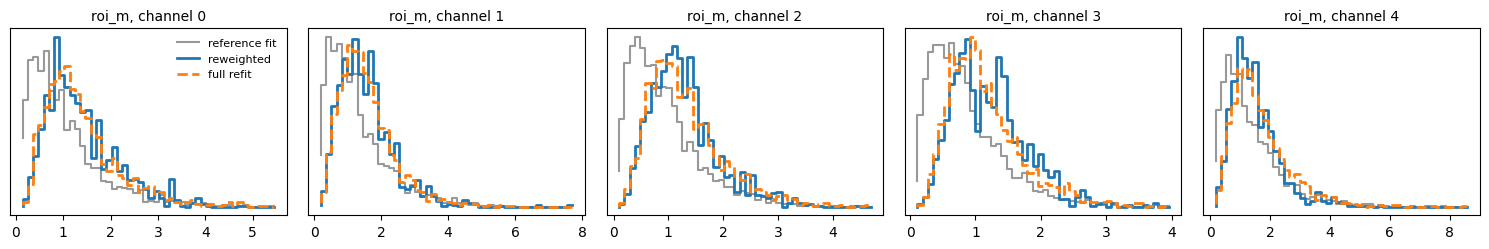

,reference,reweighted,full refit,|reweighted - refit|,... in refit SDs
"roi_m mean, channel",,,,,
0,1.060,1.437,1.434,0.003,0.004
1,1.341,1.630,1.629,0.001,0.001
2,0.968,1.328,1.361,0.033,0.047
3,0.881,1.243,1.188,0.054,0.095
4,1.402,1.567,1.751,0.184,0.182


In [11]:
r_roi = try_prior("roi_m", lognormal(0.5, 0.6), mmm, seed=SEED + 1)

## 4. A new `eta_m` prior
`eta_m` is the scale of the media effect across geos, a key parameter of geo-level models. The prior shrinks from `HalfNormal(1)` to `HalfNormal(0.5)`.
The reference prior must cover the new one: a *longer* upper tail than `HalfNormal(1)` would need draws the reference fit does not contain.

reweighting took 0.003 s
k-hat = -0.19, ESS = 15% of the draws  ->  USE IT


fit: 121 s


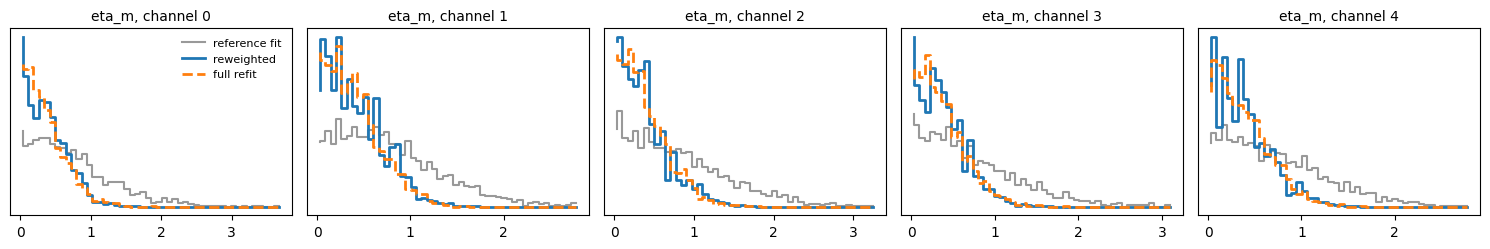

,reference,reweighted,full refit,|reweighted - refit|,... in refit SDs
"eta_m mean, channel",,,,,
0,0.752,0.384,0.376,0.008,0.029
1,0.788,0.427,0.402,0.025,0.089
2,0.825,0.393,0.396,0.003,0.011
3,0.733,0.388,0.388,0.000,0.000
4,0.738,0.390,0.390,0.000,0.001


In [12]:
r_eta = try_prior("eta_m", halfnormal(0.5), mmm, seed=SEED + 2)

## 5. A sensitivity sweep with no refits
The real use case: several candidate priors, one table. **refit** rows are priors the reference draws cannot answer; run a real fit for them. Their means are left out on purpose.

In [13]:
def sweep(param, candidates):
    x = draws_of(mmm, param)
    rows = []
    for label, prior in candidates.items():
        r = psis(log_ratio(x, prior[1], REFERENCE[param][1]), reff)
        means = weighted_mean(x, r["w"]) if r["verdict"] != "refit" else np.full(x.shape[1], np.nan)
        rows.append({f"new {param} prior": label, "k-hat": r["k_hat"], "ESS %": r["ess_pct"], "verdict": r["verdict"],
                     **{f"{param} ch{j}": m for j, m in enumerate(means)}})
    reference_row = {f"new {param} prior": "reference fit", "k-hat": np.nan, "ESS %": 100.0, "verdict": "-",
                     **{f"{param} ch{j}": m for j, m in enumerate(x.mean(0))}}
    return pd.DataFrame([reference_row] + rows).set_index(f"new {param} prior")


sweep("roi_m", {
    "LogNormal(0.2, 0.6)  same median, tighter": lognormal(0.2, 0.6),
    "LogNormal(0.2, 1.2)  same median, wider": lognormal(0.2, 1.2),
    "LogNormal(0.0, 0.9)  lower": lognormal(0.0, 0.9),
    "LogNormal(0.4, 0.9)  higher": lognormal(0.4, 0.9),
    "LogNormal(0.6, 0.6)  higher, tight": lognormal(0.6, 0.6),
    "LogNormal(0.8, 0.5)  far": lognormal(0.8, 0.5),
    "LogNormal(1.2, 0.45) very far": lognormal(1.2, 0.45),
})

,k-hat,ESS %,verdict,roi_m ch0,roi_m ch1,roi_m ch2,roi_m ch3,roi_m ch4
new roi_m prior,,,,,,,,
reference fit,NaN,100.000,-,1.060,1.341,0.968,0.881,1.402
"LogNormal(0.2, 0.6) same median, tighter",-0.219,50.034,use it,1.173,1.338,1.103,1.047,1.340
"LogNormal(0.2, 1.2) same median, wider",0.591,30.574,check,0.934,1.323,0.838,0.748,1.527
"LogNormal(0.0, 0.9) lower",0.201,85.505,use it,0.946,1.202,0.867,0.800,1.274
"LogNormal(0.4, 0.9) higher",0.016,87.705,use it,1.174,1.486,1.067,0.961,1.527
"LogNormal(0.6, 0.6) higher, tight",0.122,14.150,use it,1.534,1.735,1.401,1.300,1.633
"LogNormal(0.8, 0.5) far",0.780,2.152,refit,NaN,NaN,NaN,NaN,NaN
"LogNormal(1.2, 0.45) very far",2.087,0.317,refit,NaN,NaN,NaN,NaN,NaN


In [14]:
sweep("eta_m", {
    "HalfNormal(0.7)": halfnormal(0.7),
    "HalfNormal(0.5)": halfnormal(0.5),
    "HalfNormal(0.35)": halfnormal(0.35),
    "HalfNormal(0.2)  strong shrinkage": halfnormal(0.2),
})

,k-hat,ESS %,verdict,eta_m ch0,eta_m ch1,eta_m ch2,eta_m ch3,eta_m ch4
new eta_m prior,,,,,,,,
reference fit,NaN,100.000,-,0.752,0.788,0.825,0.733,0.738
HalfNormal(0.7),-0.401,50.480,use it,0.532,0.582,0.570,0.520,0.535
HalfNormal(0.5),-0.186,14.851,use it,0.384,0.427,0.393,0.388,0.390
HalfNormal(0.35),0.372,3.757,use it,0.278,0.319,0.292,0.297,0.291
HalfNormal(0.2) strong shrinkage,3.571,0.573,refit,NaN,NaN,NaN,NaN,NaN


## Limits
- **Only the prior changes.** Same data, model structure and likelihood. A different `media_prior_type`, new controls or a new likelihood need a refit.
- **Support.** The new prior must put its mass where the reference prior does; draws with zero density under the new prior get weight 0.
- **Point-mass priors cannot be reweighted**, e.g. Meridian's default `slope_m = Deterministic(1.0)`.
- **Tested on Meridian 2.1.0 (JAX)** with the demo data. The evidence behind the k̂ thresholds is in `evidence/`.